In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

filename = "cleaned_trizod_dataset.csv"
df = pd.read_csv(filename, index_col="label", converters={"gscores": lambda x: np.array(json.loads(x), dtype=float)})
df

,is_test,entity_name,cluster_size,sequence,temperature,pH,ionic_strength,total_bbshifts,mean_gscore,gscores
label,,,,,,,,,,
9_1_1_1,False,carboxypeptidase inhibitor,3,XQHADPICNKPCKTHDDCSGAWFCQACWNSARTCGPYVG,308.0,3.82,0.1000,102.0,0.090743,"[nan, 0.2454, 0.3479, 0.3993, 0.3947, 0.2264, ..."
26_1_1_1,False,glycoprotein D-1,1,MADPNRFRGKDLPVLDQLTDPP,293.0,4.70,0.1000,55.0,0.706490,"[nan, 0.8055, 0.7937, 0.6111, 0.3137, 0.4028, ..."
32_1_1_1,False,lac repressor headpiece,9,MKPVTLYDVAEYAGVSYQTVSRVVNQASHVSAKTREKVEAAMAELN...,291.0,6.85,0.1000,121.0,0.123321,"[nan, nan, 0.1458, 0.0797, 0.0859, 0.0887, 0.1..."
41_1_1_1,False,neutrophil NP-5,1,VFCTCRGFLCGSGERASGSCTINGVRHTLCCRR,293.0,3.50,0.1000,88.0,0.103945,"[nan, 0.1615, 0.1117, 0.1094, 0.0774, 0.1508, ..."
58_1_1_1,False,ribosomal protein E-L30,2,AKTIKITQTXSAIGRLXXHKATLLGLGLRRIGHTVEREDTXAIRGM...,298.0,6.80,0.1000,150.0,0.081548,"[nan, 0.0083, 0.0055, 0.0439, 0.0372, 0.0372, ..."
...,...,...,...,...,...,...,...,...,...,...
53400_1_1_1,False,entity_1,1,KCGSLGNIHHKPGGGQVEVKSEKLDFKDRVQSKIGSLDNITHVPGG...,298.0,7.40,0.1617,238.0,0.854909,"[nan, nan, nan, 0.9551, 0.9564, 0.7819, 0.6935..."
53421_1_1_1,False,entity_1,1,MSGSHHHHHHSSGIEGRGRENLYFQGQVQLVESGGGVVQPGRSLRL...,313.0,6.50,0.1250,691.0,0.139209,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
7222_12_1_1,False,Link_TSG6,33,GVYHREARSGKYKLTYAEAKAVCEFEGGHLATYKQLEAARKIGFHV...,298.0,7.50,0.1000,178.0,0.104102,"[nan, 0.0318, 0.0845, 0.0565, 0.1077, 0.0678, ..."


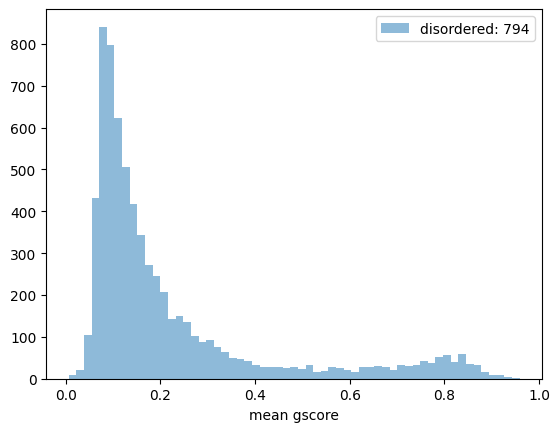

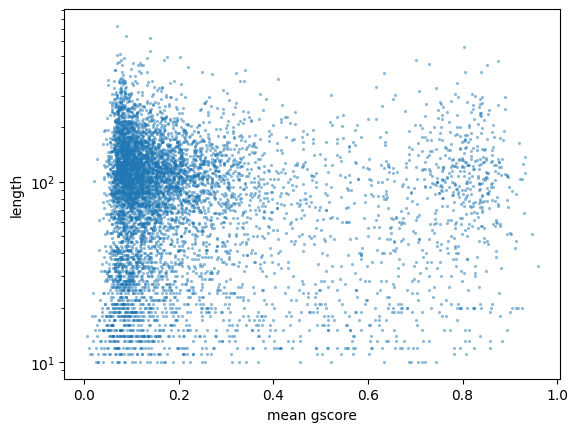

In [2]:
plt.hist(df["mean_gscore"], bins="auto", alpha=0.5, label=f"disordered: {sum(df['mean_gscore'] >= 0.5)}")
plt.xlabel("mean gscore")
plt.legend()
plt.show()

plt.scatter(df["mean_gscore"], df["sequence"].apply(len), alpha=0.5, s=5, lw=0)
plt.xlabel("mean gscore")
plt.ylabel("length")
plt.yscale("log")
plt.show()

size of the test set: 158, of which 79 disordered (ratio 0.50)
size of the train set: 6_631, of which 715 disordered (ratio 0.11)


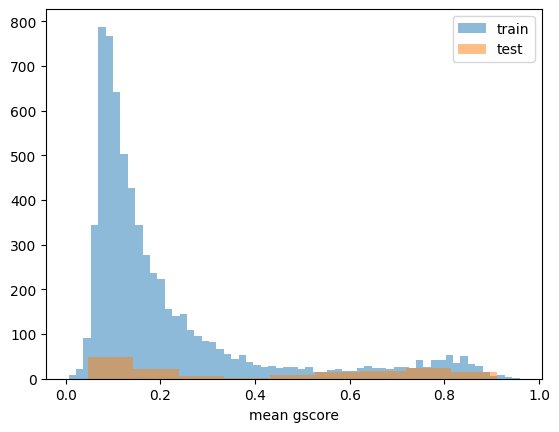

In [3]:
print(
    f"size of the test set: {sum(df['is_test']):_}, of which {sum(df['is_test'] & (df['mean_gscore'] >= 0.5)):_} disordered (ratio {sum(df['is_test'] & (df['mean_gscore'] >= 0.5)) / sum(df['is_test']):.2f})",
)
print(
    f"size of the train set: {sum(~df['is_test']):_}, of which {sum(~df['is_test'] & (df['mean_gscore'] >= 0.5)):_} disordered (ratio {sum(~df['is_test'] & (df['mean_gscore'] >= 0.5)) / sum(~df['is_test']):.2f})",
)
plt.hist(df[~df["is_test"]].loc[:, "mean_gscore"], bins="auto", alpha=0.5, label="train")
plt.hist(df[df["is_test"]].loc[:, "mean_gscore"], bins="auto", alpha=0.5, label="test")
plt.xlabel("mean gscore")
plt.legend()
plt.show()

Data-driven parameters:
  target_ratio = 2.00 (desired effective ordered/disordered ratio)
  a = 21.885 (scaled from original ratio 5.471)
  b = 10.644 (steepness, derived from transition zone)
  Transition zone: [0.207, 0.583], width = 0.376

Effective samples after weighting:
  Ordered (< 0.5):    181835.7 (was 536844)
  Disordered (>= 0.5): 98120.0 (was 98120)
  Ratio: 1.853 (was 5.471)

Set these values in src/config.py:
REBALANCE_A = 21.885
REBALANCE_B = 10.644


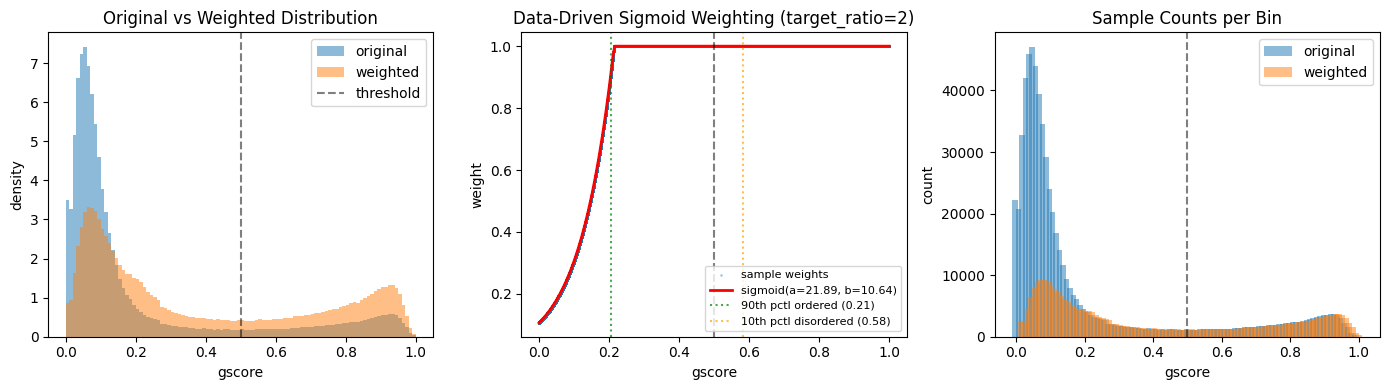

weights_mean.min(): 0.0016202148404621391


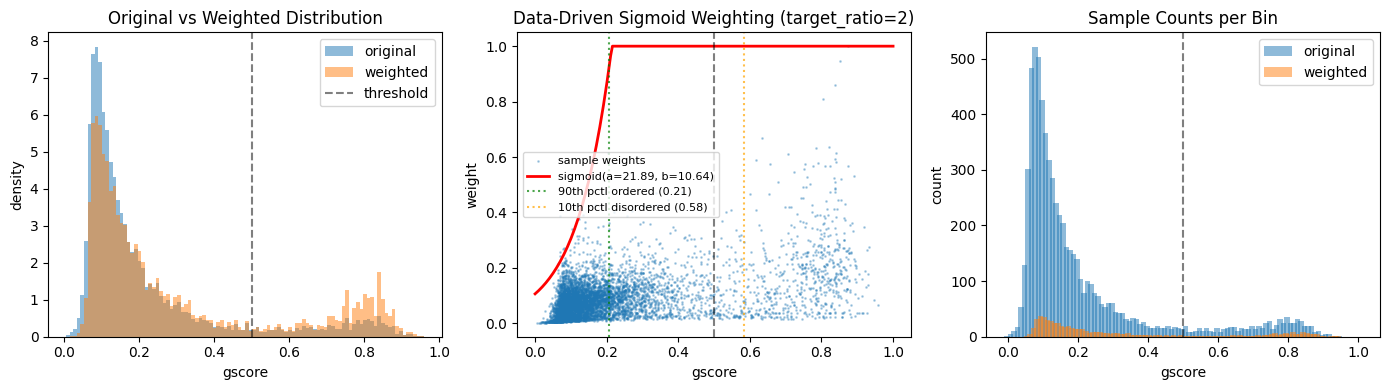

In [4]:
# Data-driven sigmoid weighting scheme for balancing the training set
# -------------------------------------------------------------------

# Tune this parameter to control the balance:
# 1.0 = fully balanced, 2.0 = 2x more ordered, 0.5 = 2x more disordered
TARGET_RATIO = 2
# Apply to training data (all residues)
y_train = np.concatenate(df[~df["is_test"]]["gscores"].values)
y_train = y_train[np.isfinite(y_train)]


def compute_data_driven_weights(y, threshold=0.5, target_ratio=1.0):
    """
    Computes sample weights using a sigmoid-like function where parameters
    are derived from the data distribution rather than being arbitrary.

    Parameters:
    - y: array of scores
    - threshold: decision boundary (default 0.5)
    - target_ratio: desired ratio of effective ordered/disordered samples after weighting
                    1.0 = fully balanced (default)
                    2.0 = ordered samples 2x more than disordered
                    0.5 = disordered samples 2x more than ordered

    Parameters derived from data:
    - a: scaled class imbalance ratio to achieve target_ratio
    - b: steepness from the "transition zone" width around the threshold
    """
    # 1. Derive 'a' from class imbalance ratio, scaled by target_ratio
    n_ordered = np.sum(y < threshold)
    n_disordered = np.sum(y >= threshold)
    original_ratio = n_ordered / n_disordered
    # Scale 'a' so that effective_ordered / effective_disordered = target_ratio
    a = original_ratio * 2 * target_ratio

    # 2. Derive 'b' from the spread of scores around the threshold
    # Use the gap between high-ordered and low-disordered scores
    ordered_scores = y[y < threshold]
    disordered_scores = y[y >= threshold]

    q_high_ordered = np.percentile(ordered_scores, 90)  # top of ordered
    q_low_disordered = np.percentile(disordered_scores, 10)  # bottom of disordered
    transition_width = max(q_low_disordered - q_high_ordered, 0.1)  # avoid division by small numbers

    # Sigmoid spans ~(0.02, 0.98) over ±2/b, so 4/b ≈ transition width
    b = 4.0 / transition_width

    # 3. Apply the sigmoid weighting
    weights = np.minimum(1.0, a / (1 + np.exp(-b * (y - threshold))))
    assert weights.min() >= 0.0, f"better not to loose datapoints: {weights.min()}"

    return weights, a, b, q_high_ordered, q_low_disordered


weights, a, b, q_high, q_low = compute_data_driven_weights(y_train, target_ratio=TARGET_RATIO)
original_ratio = sum(y_train < 0.5) / sum(y_train >= 0.5)
print("Data-driven parameters:")
print(f"  target_ratio = {TARGET_RATIO:.2f} (desired effective ordered/disordered ratio)")
print(f"  a = {a:.3f} (scaled from original ratio {original_ratio:.3f})")
print(f"  b = {b:.3f} (steepness, derived from transition zone)")
print(f"  Transition zone: [{q_high:.3f}, {q_low:.3f}], width = {q_low - q_high:.3f}")
print()
print("Effective samples after weighting:")
print(f"  Ordered (< 0.5):    {weights[y_train < 0.5].sum():.1f} (was {sum(y_train < 0.5)})")
print(f"  Disordered (>= 0.5): {weights[y_train >= 0.5].sum():.1f} (was {sum(y_train >= 0.5)})")
print(
    f"  Ratio: {weights[y_train < 0.5].sum() / weights[y_train >= 0.5].sum():.3f} (was {sum(y_train < 0.5) / sum(y_train >= 0.5):.3f})",
)
print("\nSet these values in src/config.py:")
print(f"REBALANCE_A = {a:.3f}")
print(f"REBALANCE_B = {b:.3f}")


def visualize_weights(y_train, weights):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    ax = axes[0]
    ax.hist(y_train, bins=100, alpha=0.5, label="original", density=True)
    ax.hist(y_train, weights=weights, bins=100, alpha=0.5, label="weighted", density=True)
    ax.axvline(0.5, color="k", linestyle="--", alpha=0.5, label="threshold")
    ax.set_xlabel("gscore")
    ax.set_ylabel("density")
    ax.set_title("Original vs Weighted Distribution")
    ax.legend()

    ax = axes[1]
    x_sorted = np.sort(y_train)
    w_sorted = weights[np.argsort(y_train)]
    ax.scatter(x_sorted, w_sorted, s=1, alpha=0.3, label="sample weights")
    x_curve = np.linspace(0, 1, 200)
    w_curve = np.minimum(1.0, a / (1 + np.exp(-b * (x_curve - 0.5))))
    ax.plot(x_curve, w_curve, "r-", lw=2, label=f"sigmoid(a={a:.2f}, b={b:.2f})")
    ax.axvline(0.5, color="k", linestyle="--", alpha=0.5)
    ax.axvline(q_high, color="g", linestyle=":", alpha=0.7, label=f"90th pctl ordered ({q_high:.2f})")
    ax.axvline(q_low, color="orange", linestyle=":", alpha=0.7, label=f"10th pctl disordered ({q_low:.2f})")
    ax.set_xlabel("gscore")
    ax.set_ylabel("weight")
    ax.set_title(f"Data-Driven Sigmoid Weighting (target_ratio={TARGET_RATIO})")
    ax.legend(fontsize=8)

    # Plot 3: Cumulative effective samples
    ax = axes[2]
    bins = np.linspace(0, 1, 101)
    orig_counts, _ = np.histogram(y_train, bins=bins)
    weighted_counts, _ = np.histogram(y_train, bins=bins, weights=weights)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    ax.bar(bin_centers - 0.008, orig_counts, width=0.016, alpha=0.5, label="original")
    ax.bar(bin_centers + 0.008, weighted_counts, width=0.016, alpha=0.5, label="weighted")
    ax.axvline(0.5, color="k", linestyle="--", alpha=0.5)
    ax.set_xlabel("gscore")
    ax.set_ylabel("count")
    ax.set_title("Sample Counts per Bin")
    ax.legend()

    plt.tight_layout()
    plt.show()


visualize_weights(y_train, weights)
y_train_mean = df[~df["is_test"]]["mean_gscore"].values
weights_mean = []
start = 0
for label in df[~df["is_test"]].index:
    end = start + np.sum(np.isfinite(df.loc[label, "gscores"]))
    weights_mean.append(np.sum(weights[start:end]))
    start = end
weights_mean = np.array(weights_mean) / np.max(weights_mean)
print(f"weights_mean.min(): {weights_mean.min()}")
visualize_weights(y_train_mean, weights_mean)